In [ ]:
# MUSLIM ZAIN 24F-AI-031

In [50]:
# Part 1: Import Required Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, ConfusionMatrixDisplay

In [51]:
# Part 2: Load Dataset

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
print(df.head())

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLevel  \
0  ...

In [52]:
# Part 3: Data Preprocessing
# Step 1: Check Missing Values

print(df.isnull().sum())

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [53]:
# Step 2: Clean Dataset
df = df.dropna()
df = df.drop(columns=[
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
])

In [54]:
# Step 3: Convert Categorical Data into Numeric

encoder = LabelEncoder()
for column in df.select_dtypes(include="object").columns:
    df[column] = encoder.fit_transform(df[column])

C:\Users\musli\AppData\Local\Temp\ipykernel_11972\2043963447.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


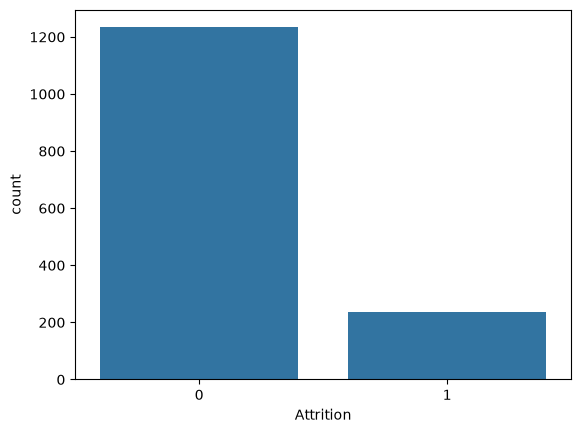

In [55]:
# Part 4: Data Visualization
sns.countplot(x="Attrition", data=df)
plt.show()

In [56]:
# Part 5: Split Dataset
X = df.drop("Attrition", axis=1)
y = df["Attrition"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [57]:
# Part 6: Train Three Machine Learning Models
# 1. Logistic Regression

lr = LogisticRegression(max_iter=2000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

C:\Users\musli\AppData\Roaming\Python\Python314\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [58]:
# 2. Decision Tree

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)    

In [59]:
# 3. Random Forest

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [60]:

from sklearn.ensemble import RandomForestClassifier

In [61]:
# Part 7: Model Evaluation – F1 Score

print("Logistic Regression F1:", f1_score(y_test, lr_pred))
print("Decision Tree F1:", f1_score(y_test, dt_pred))
print("Random Forest F1:", f1_score(y_test, rf_pred))

Logistic Regression F1: 0.3076923076923077
Decision Tree F1: 0.23376623376623376
Random Forest F1: 0.2222222222222222


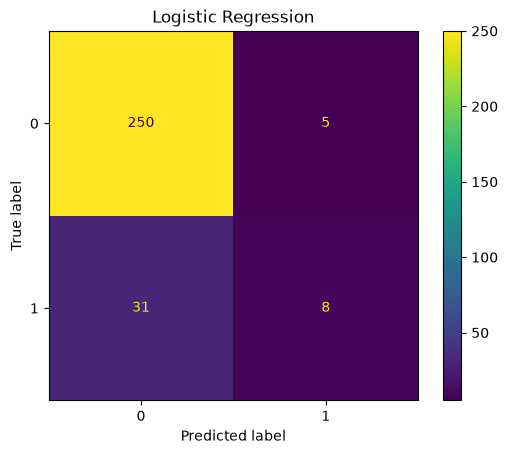

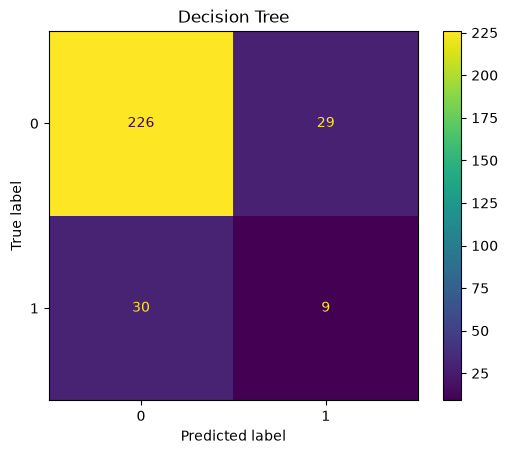

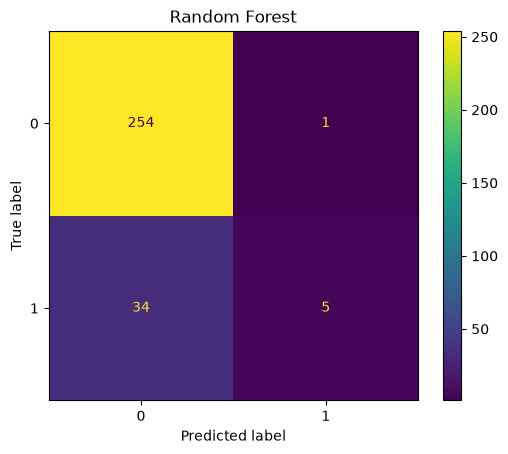

In [62]:
# Part 8: Confusion Matrix

ConfusionMatrixDisplay.from_predictions(y_test, lr_pred)
plt.title("Logistic Regression")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, dt_pred)
plt.title("Decision Tree")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred)
plt.title("Random Forest")
plt.show()

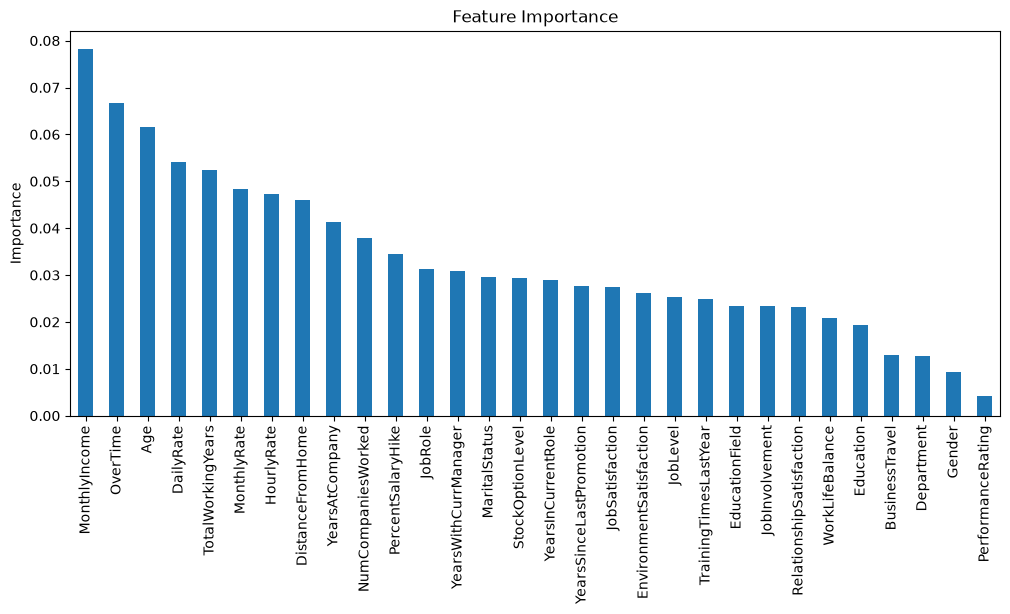

In [63]:
# Part 9: Feature Importance Visualization

importance = pd.Series(rf.feature_importances_, index=X.columns)
importance = importance.sort_values(ascending=False)
importance.plot(kind="bar", figsize=(12, 5))
plt.title("Feature Importance")
plt.ylabel("Importance")
plt.show()